To run model, it is highly recommended to create a virtual environment.

Make sure all files are in the same directory as this Jupytr notebook

List of required files:

OAcombined.csv
holdout_data.csv
train_data.csv


Windows
Open powershell and choose working dir

Create virtual environment
python -m venv .venv

Activate it
.venv\Scripts\Activate.ps1

MacOS

Open terminal and choose working dir

Create virtual environment
python3 -m venv .venv

Activate it
source .venv/bin/activate

It should say .(venv) at the beginning

Install the required libraries
pandas 1.5.3
numpy 1.26.4
scikit-learn 1.4.2
imblearn 0.12.3
catboost 1.2.3
pycaret 3.3.2
shap 0.47.1
matplotlib 3.7.5


Run notebook below



In [ ]:
# Step 1
# Import required libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, validation_curve, learning_curve, StratifiedKFold
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import (
    roc_curve, auc, precision_recall_curve,
    average_precision_score, confusion_matrix, ConfusionMatrixDisplay
)
from imblearn.over_sampling import SMOTE
from catboost import CatBoostClassifier
from pycaret.classification import *
import shap
import matplotlib.pyplot as plt


In [ ]:
from matplotlib.colors import LinearSegmentedColormap
import os

In [ ]:
# Step 2
# Set working directory to where OAcombined.csv is

df = pd.read_csv("OAcombined.csv")
df = df.set_index("index")
# One hot encoding
df['Condition'] = df['Condition'].map(lambda x: 0 if x == 'Healthy' else 1)


Do not use the next code block (Step 3) because that was to generate holdout data to be reproducible you start from the next block instead (Step 4)

In [ ]:
# Step 3
# Ensure 'data' directory exists
os.makedirs("data", exist_ok=True)

# Split the data once
train_data, holdout_data = train_test_split(
    df,
    test_size=0.1,
    stratify=df["Condition"],
    random_state=123
)

# Save to CSV
train_data.to_csv("data/train_data.csv", index=False)
holdout_data.to_csv("data/holdout_data.csv", index=False)

# Proceed as usual
df_remaining = train_data.reset_index(drop=True)

# Check and encode "Species" only if it exists
if 'Species' in df_remaining.columns:
    print("Encoding 'Species' column...")
    print("Unique values:", df_remaining['Species'].unique())  # Optional debug
    df_remaining = pd.get_dummies(df_remaining, columns=["Species"], drop_first=True)
else:
    print("'Species' column is already encoded or missing — skipping.")

# Now it's safe to get feature columns
features = [col for col in df_remaining.columns if col != "Condition"]


Encoding 'Species' column...
Unique values: ['Human' 'Horse' 'Dog']


Reviewers continue on here

In [ ]:
# Step 4
# This is for the reviewers only
# Load pre-saved split for reproducibility
train_data = pd.read_csv("data/train_data.csv")
holdout_data = pd.read_csv("data/holdout_data.csv")

df_remaining = train_data.reset_index(drop=True)


In [ ]:
# Step 5
# Create External Datasets 

# 1. External SMOTE only
smote = SMOTE(random_state=123)
X_sm, y_sm = smote.fit_resample(df_remaining[features], df_remaining["Condition"])
ds_smote = pd.DataFrame(X_sm, columns=features)
ds_smote["Condition"] = y_sm
ds_smote = ds_smote.reset_index(drop=True)

# 2. External Polynomial only
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(df_remaining[features])
poly_feature_names = poly.get_feature_names_out(features)
ds_poly = pd.DataFrame(X_poly, columns=poly_feature_names)
ds_poly["Condition"] = df_remaining["Condition"].reset_index(drop=True)
ds_poly = ds_poly.reset_index(drop=True)

# 3. External SMOTE + Polynomial (apply SMOTE first, then Polynomial)
X_sp, y_sp = smote.fit_resample(df_remaining[features], df_remaining["Condition"])
poly_sp = PolynomialFeatures(degree=2, include_bias=False)
X_sp_poly = poly_sp.fit_transform(X_sp)
poly_sp_feature_names = poly_sp.get_feature_names_out(features)
ds_smote_poly = pd.DataFrame(X_sp_poly, columns=poly_sp_feature_names)
ds_smote_poly["Condition"] = y_sp
ds_smote_poly = ds_smote_poly.reset_index(drop=True)

# Store the external datasets in a dictionary for easy looping
external_datasets = {
    "SMOTE": ds_smote,
    "Polynomial": ds_poly,
    "SMOTE_Polynomial": ds_smote_poly
}

#  Define Internal PyCaret Configurations 
pycaret_configs = [
    {"normalize": True, "normalize_method": "zscore"}
]

results_list = []

#  Loop Over External Datasets and Internal Configurations 
for ds_name, ds_data in external_datasets.items():
    for i, config in enumerate(pycaret_configs, start=1):
        print(f"\nRunning dataset '{ds_name}' with internal config {i}: {config}")
        setup(
            data=ds_data,
            target="Condition",
            session_id=123,
            data_split_stratify=True,  # Ensures the internal split is stratified on 'Condition'
            verbose=False,
            **config
        )
        best_model = compare_models()  # Compare models using PyCaret
        leaderboard = pull()           # Retrieve the leaderboard from PyCaret
        leaderboard["Dataset"] = ds_name
        leaderboard["Config"] = f"Config_{i}"
        results_list.append(leaderboard)

final_results = pd.concat(results_list, ignore_index=True)
final_results.to_csv("model_comparison_results.csv", index=False)
print("\nResults saved to model_comparison_results.csv")



Running dataset 'SMOTE' with internal config 1: {'normalize': True, 'normalize_method': 'zscore'}


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
et,Extra Trees Classifier,0.9283,0.9849,0.9155,0.9500,0.9276,0.8568,0.8655,0.0130
lightgbm,Light Gradient Boosting Machine,0.9186,0.9668,0.8782,0.9624,0.9129,0.8378,0.8487,0.1340
catboost,CatBoost Classifier,0.9086,0.9842,0.8573,0.9652,0.9007,0.8174,0.8323,0.5950
xgboost,Extreme Gradient Boosting,0.9083,0.9619,0.8764,0.9431,0.9026,0.8169,0.8272,0.0100
rf,Random Forest Classifier,0.8990,0.9768,0.8582,0.9465,0.8924,0.7986,0.8132,0.0150
gbc,Gradient Boosting Classifier,0.8605,0.9527,0.8100,0.9125,0.8473,0.7220,0.7398,0.0220
lr,Logistic Regression,0.8510,0.9178,0.7900,0.9176,0.8326,0.7013,0.7233,0.1800
qda,Quadratic Discriminant Analysis,0.8507,0.9609,1.0000,0.7769,0.8728,0.7001,0.7363,0.0040
ada,Ada Boost Classifier,0.8417,0.9297,0.7909,0.9002,0.8289,0.6842,0.7043,0.0100
ridge,Ridge Classifier,0.8317,0.8942,0.7500,0.9171,0.8026,0.6624,0.6911,0.0030



Running dataset 'Polynomial' with internal config 1: {'normalize': True, 'normalize_method': 'zscore'}


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
ada,Ada Boost Classifier,0.8519,0.9053,0.9327,0.8781,0.9030,0.5820,0.5953,0.1010
lightgbm,Light Gradient Boosting Machine,0.8376,0.9171,0.9527,0.8531,0.8982,0.4966,0.5221,0.2770
lr,Logistic Regression,0.8300,0.8805,0.9327,0.8533,0.8902,0.5024,0.5145,0.0220
ridge,Ridge Classifier,0.8300,0.8615,0.9127,0.8685,0.8874,0.5308,0.5520,0.0220
xgboost,Extreme Gradient Boosting,0.8300,0.9064,0.9318,0.8567,0.8899,0.4933,0.5141,0.1120
rf,Random Forest Classifier,0.8081,0.9141,0.9418,0.8241,0.8780,0.4246,0.4506,0.0370
lda,Linear Discriminant Analysis,0.7948,0.7794,0.9136,0.8291,0.8659,0.4173,0.4473,0.0400
knn,K Neighbors Classifier,0.7876,0.8489,0.9600,0.7934,0.8676,0.3181,0.3635,0.0210
svm,SVM - Linear Kernel,0.7871,0.8272,0.7864,0.9222,0.8407,0.5071,0.5452,0.0210
catboost,CatBoost Classifier,0.7871,0.9235,0.9518,0.8009,0.8675,0.3305,0.3716,13.5120



Running dataset 'SMOTE_Polynomial' with internal config 1: {'normalize': True, 'normalize_method': 'zscore'}


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
et,Extra Trees Classifier,0.9379,0.9817,0.9255,0.9576,0.9368,0.8761,0.8837,0.0310
catboost,CatBoost Classifier,0.9281,0.9855,0.8964,0.9652,0.9249,0.8565,0.8658,18.9210
gbc,Gradient Boosting Classifier,0.9231,0.9744,0.8764,0.9709,0.9177,0.8465,0.8554,0.6150
rf,Random Forest Classifier,0.9138,0.9895,0.8964,0.9436,0.9120,0.8281,0.8411,0.0410
lightgbm,Light Gradient Boosting Machine,0.9086,0.9796,0.8773,0.9457,0.9046,0.8175,0.8286,0.3580
xgboost,Extreme Gradient Boosting,0.8940,0.9677,0.8482,0.9413,0.8844,0.7890,0.8014,0.1690
lr,Logistic Regression,0.8898,0.9465,0.8491,0.9340,0.8829,0.7799,0.7927,0.1150
ada,Ada Boost Classifier,0.8745,0.9337,0.8464,0.9042,0.8702,0.7494,0.7575,0.1450
ridge,Ridge Classifier,0.8698,0.9582,0.7909,0.9509,0.8531,0.7407,0.7629,0.0200
svm,SVM - Linear Kernel,0.8607,0.9245,0.8300,0.8994,0.8557,0.7223,0.7357,0.0220



Results saved to model_comparison_results.csv


In [ ]:
# Step 6
# Since SMOTE only was the best we retrained data that only had SMOTE to address class imbalance

setup(
    data=ds_smote,
    target="Condition",
    session_id=123,
    verbose=False,
    data_split_stratify=True,
    normalize=True,
    normalize_method="zscore"
)

cat = create_model("catboost")
# you can tune it but it isn't better than the original model, you'll have to use tuned_cat instead of cat if you do
tuned_cat = tune_model(cat, optimize='AUC')
final_cat = finalize_model(cat)


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.9048,0.9909,0.9091,0.9091,0.9091,0.8091,0.8091
1,0.9048,0.9545,0.8182,1.0000,0.9000,0.8108,0.8257
2,0.9048,1.0000,0.8182,1.0000,0.9000,0.8108,0.8257
3,0.8571,0.9545,0.7273,1.0000,0.8421,0.7175,0.7480
4,0.9048,1.0000,1.0000,0.8333,0.9091,0.8108,0.8257
5,0.8571,1.0000,0.7000,1.0000,0.8235,0.7097,0.7416
6,0.9524,0.9818,1.0000,0.9091,0.9524,0.9050,0.9091
7,0.8500,0.9700,0.7000,1.0000,0.8235,0.7000,0.7338
8,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.9048,0.9636,0.9091,0.9091,0.9091,0.8091,0.8091
1,0.8095,0.9545,0.6364,1.0000,0.7778,0.6250,0.6742
2,0.8571,0.9545,0.7273,1.0000,0.8421,0.7175,0.7480
3,0.7619,0.9000,0.6364,0.8750,0.7368,0.5291,0.5516
4,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
5,0.8571,1.0000,0.7000,1.0000,0.8235,0.7097,0.7416
6,0.9524,0.9455,1.0000,0.9091,0.9524,0.9050,0.9091
7,0.9000,0.9700,0.9000,0.9000,0.9000,0.8000,0.8000
8,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


Fitting 10 folds for each of 10 candidates, totalling 100 fits
Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).


These parts are to run diagnositics or perfomance metrics for the model
1. We use SHAP to gain model explainability
2. We check the performance of the model on the holdout/unseen data to see if the model has good generalizability

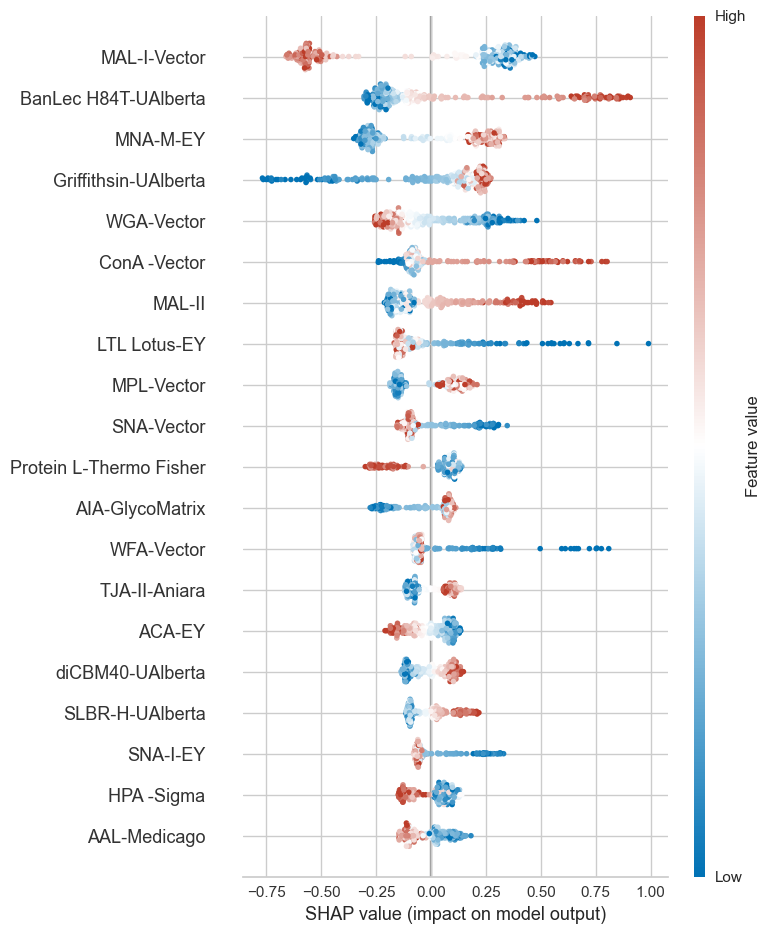

In [ ]:
# Step 7
# Set up SHAP analysis
X_train = get_config('X')
y_train = get_config('y')

model_for_shap = final_cat.steps[-1][1] if hasattr(final_cat, 'steps') else final_cat
explainer = shap.Explainer(model_for_shap, X_train)
shap_values = explainer(X_train)

# Basic SHAP Plot 
# I commented it out because we run the same thing below just using the top 20 and changing the plot colors to match ours instead of the default
#shap.summary_plot(shap_values, X_train)

# Custom Top-20 SHAP Plot
colors = ['#0072B5', 'white', '#BC3C29']
cmap = LinearSegmentedColormap.from_list("nejm_cmap", colors)

mean_abs_vals = np.abs(shap_values.values).mean(axis=0)
top20_idx = np.argsort(mean_abs_vals)[-20:][::-1]
X_top20 = X_train.iloc[:, top20_idx]
shap_vals_top20 = shap_values.values[:, top20_idx]

shap.summary_plot(shap_vals_top20, X_top20, plot_type="dot", cmap=cmap)


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,CatBoost Classifier,0.8696,0.9706,1.0000,0.8500,0.9189,0.5965,0.6519


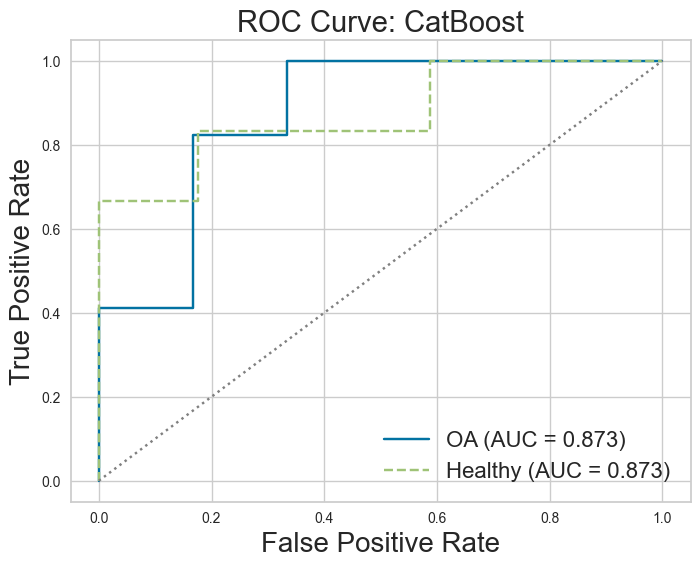

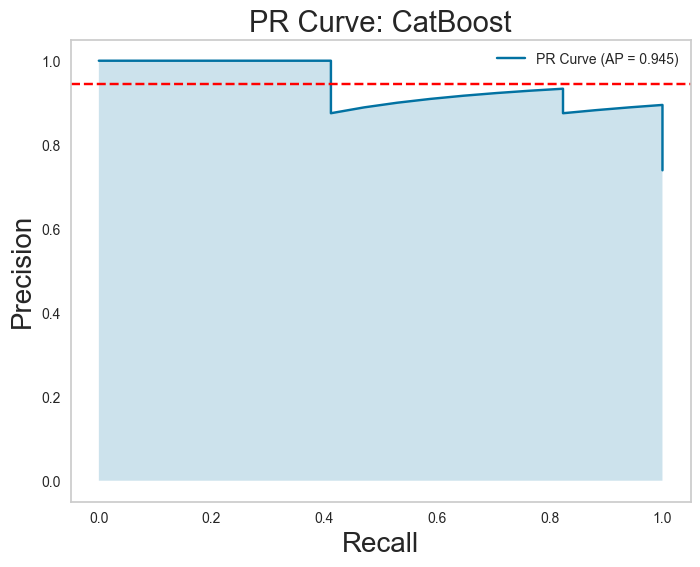

In [ ]:
# Step 8
# Make sure holdout_data is prepared
holdout_data = holdout_data.reset_index(drop=True)

# Encode Species if needed
if 'Species' in holdout_data.columns:
    holdout_data = pd.get_dummies(holdout_data, columns=['Species'], drop_first=True)

# Add missing feature columns from training
for col in df_remaining.columns:
    if col not in holdout_data.columns and col != 'Condition':
        holdout_data[col] = 0

# Align column order
holdout_data = holdout_data[df_remaining.columns]

# Predict on holdout
holdout_preds = predict_model(final_cat, data=holdout_data)

# ROC & PR curve inputs
y_true = holdout_preds['Condition']
y_probs_oa = holdout_preds['prediction_score']
y_probs_healthy = 1 - y_probs_oa

# ROC Curve
fpr_oa, tpr_oa, _ = roc_curve(y_true, y_probs_oa)
auc_oa = auc(fpr_oa, tpr_oa)
fpr_h, tpr_h, _ = roc_curve(1 - y_true, y_probs_healthy)
auc_h = auc(fpr_h, tpr_h)

plt.figure(figsize=(8, 6))
plt.plot(fpr_oa, tpr_oa, label=f"OA (AUC = {auc_oa:.3f})")
plt.plot(fpr_h, tpr_h, '--', label=f"Healthy (AUC = {auc_h:.3f})")
plt.plot([0, 1], [0, 1], ':', color='gray')
plt.xlabel("False Positive Rate", fontsize=20)
plt.ylabel("True Positive Rate", fontsize=20)
plt.legend(loc="lower right", fontsize=16)
plt.grid(True)
plt.title("ROC Curve: CatBoost", fontsize=21)
plt.show()

# PR Curve
precision, recall, _ = precision_recall_curve(y_true, y_probs_oa)
avg_precision = average_precision_score(y_true, y_probs_oa)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f"PR Curve (AP = {avg_precision:.3f})")
plt.fill_between(recall, precision, alpha=0.2)
plt.axhline(y=avg_precision, linestyle='--', color='red')
plt.xlabel("Recall", fontsize=20)
plt.ylabel("Precision", fontsize=20)
plt.title("PR Curve: CatBoost", fontsize=21)
plt.legend()
plt.grid(False)
plt.show()


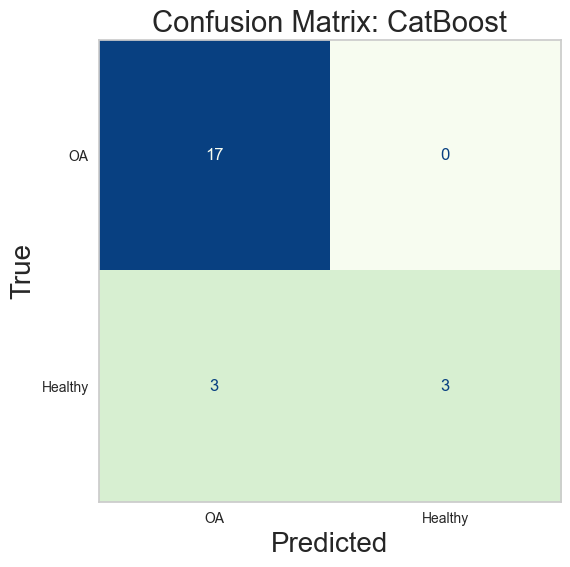

In [ ]:
# Step 9
# Generate confusion matrix to visualize the number of true positives, true negatives, false positives, and false negatives. 
# This helps understand the model's performance.

y_pred = holdout_preds['prediction_label']
cm = confusion_matrix(y_true, y_pred, labels=[1, 0])
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["OA", "Healthy"])
disp.plot(values_format='d', cmap='GnBu', ax=ax, colorbar=False)
ax.set_xlabel("Predicted", fontsize=20)
ax.set_ylabel("True", fontsize=20)
plt.title("Confusion Matrix: CatBoost", fontsize=21)
plt.grid(False)
plt.show()


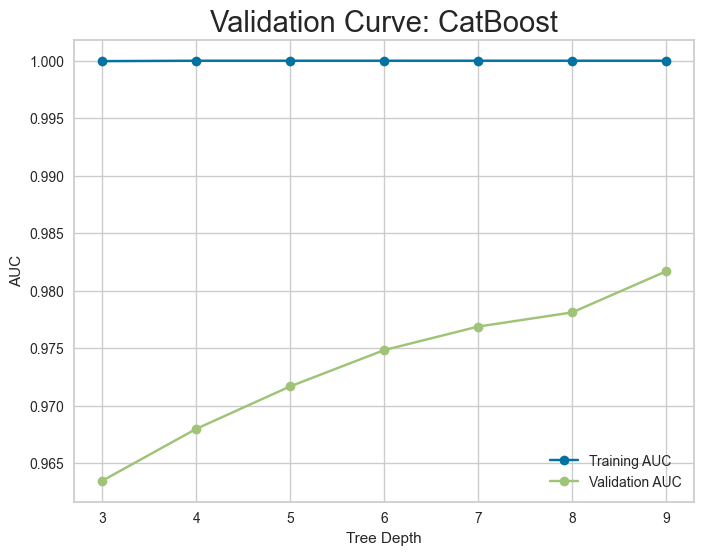

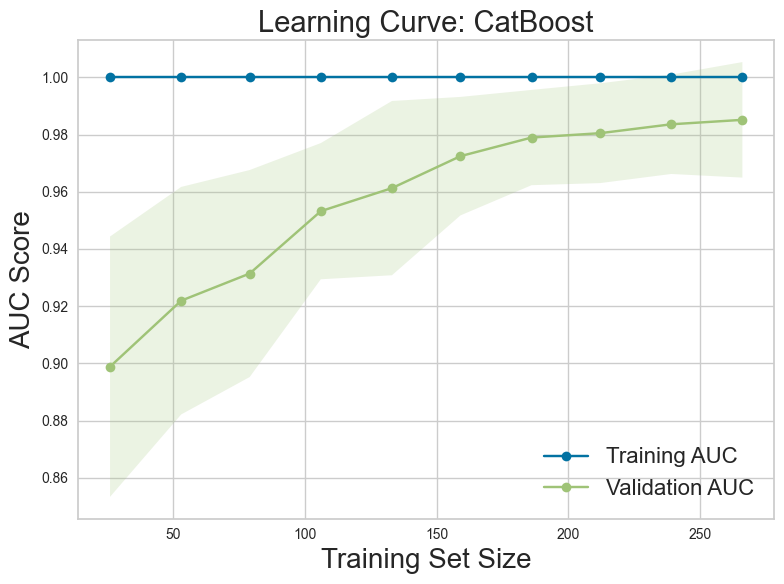

In [ ]:
# Step 9
# Generate validation curve and learning curve
# Plot a validation curve to examine how model performance varies with different values of a hyperparameter.


param_range = [3, 4, 5, 6, 7, 8, 9]

train_scores, val_scores = validation_curve(
    CatBoostClassifier(verbose=0, random_state=123),
    X_train, y_train,
    param_name="depth",
    param_range=param_range,
    scoring="roc_auc",
    cv=3
)

train_mean = np.mean(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)

plt.figure(figsize=(8, 6))
plt.plot(param_range, train_mean, 'o-', label="Training AUC")
plt.plot(param_range, val_mean, 'o-', label="Validation AUC")
plt.xlabel("Tree Depth")
plt.ylabel("AUC")
plt.legend()
plt.grid(True)
plt.title("Validation Curve: CatBoost", fontsize=21)
plt.show()

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

train_sizes, train_scores, test_scores = learning_curve(
    estimator=final_cat,
    X=X_train,
    y=y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_std = np.std(test_scores, axis=1)

plt.figure(figsize=(8, 6))
plt.plot(train_sizes, train_mean, 'o-', label="Training AUC")
plt.plot(train_sizes, test_mean, 'o-', label="Validation AUC")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.2)
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.2)
plt.title("Learning Curve: CatBoost", fontsize=21)
plt.xlabel("Training Set Size", fontsize=20)
plt.ylabel("AUC Score", fontsize=20)
plt.legend(loc="lower right", fontsize=16)
plt.grid(True)
plt.tight_layout()
plt.show()
